# Segmentación de clientes con RFM y K-Means

Este proyecto aplica técnicas de segmentación de clientes sobre el dataset **Online Retail**, que contiene transacciones de una tienda online del Reino Unido.

El objetivo es transformar los datos transaccionales en variables a nivel cliente mediante la metodología **RFM** y posteriormente aplicar **K-Means** para identificar segmentos con patrones de compra distintos.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

## 1. Carga del dataset

El dataset contiene información transaccional como número de factura, producto, cantidad, fecha, identificador de cliente y país.

In [16]:
df = pd.read_csv("../data/raw/online_retail.csv", encoding="ISO-8859-1")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [17]:
df.shape

(541909, 8)

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [19]:
df.describe(include="all")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,2011-10-31 14:41:00,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,NaN,4.611114,15287.690570,NaN
std,NaN,NaN,NaN,218.081158,NaN,96.759853,1713.600303,NaN
min,NaN,NaN,NaN,-80995.000000,NaN,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.130000,16791.000000,NaN


## 2. Exploración inicial

En esta etapa se revisa el tamaño del dataset, los tipos de variables, los valores faltantes y la estructura general antes de realizar el preprocesamiento.

In [20]:
missing = df.isnull().sum().sort_values(ascending=False)
missing[missing > 0]

CustomerID     135080
Description      1454
dtype: int64

In [21]:
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
missing_pct[missing_pct > 0]

CustomerID     24.926694
Description     0.268311
dtype: float64

Se observan valores faltantes, principalmente en `CustomerID` y `Description`. Dado que la segmentación requiere identificar clientes, los registros sin `CustomerID` serán eliminados.

## 3. Limpieza de datos

Se aplican las siguientes reglas de limpieza:

- Eliminar filas con `CustomerID` nulo
- Excluir transacciones canceladas
- Eliminar cantidades menores o iguales a cero
- Eliminar precios unitarios menores o iguales a cero

In [22]:
df = df.dropna(subset=["CustomerID"])

In [23]:
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

In [24]:
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]

In [25]:
df.shape

(397884, 8)

In [26]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 4. Preparación de variables

Para construir indicadores a nivel cliente, la variable de fecha debe convertirse a formato datetime y además se calcula el valor total de cada línea de compra:

`TotalPrice = Quantity × UnitPrice`

In [27]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["CustomerID"] = df["CustomerID"].astype(str)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

In [28]:
df[["Quantity", "UnitPrice", "TotalPrice"]].describe()

,Quantity,UnitPrice,TotalPrice
count,397884.000000,397884.000000,397884.000000
mean,12.988238,3.116488,22.397000
std,179.331775,22.097877,309.071041
min,1.000000,0.001000,0.001000
25%,2.000000,1.250000,4.680000
50%,6.000000,1.950000,11.800000
75%,12.000000,3.750000,19.800000
max,80995.000000,8142.750000,168469.600000


## 5. Distribuciones numéricas a nivel transacción

Antes de construir la tabla RFM, se analizan las distribuciones de las variables numéricas transaccionales para detectar sesgo y posibles valores extremos.

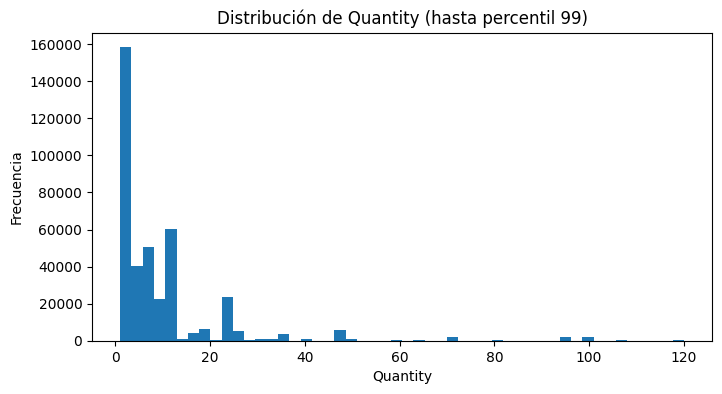

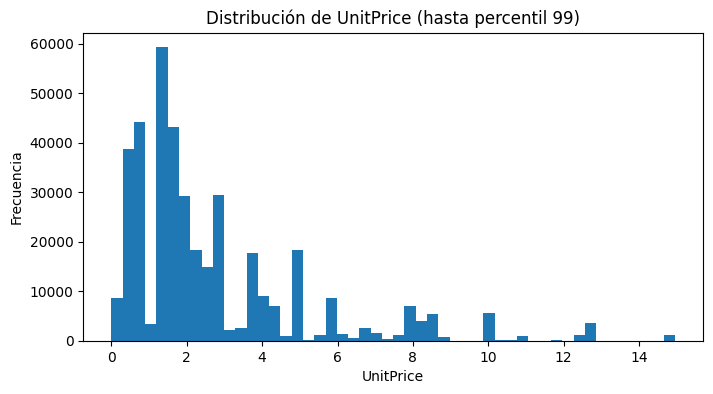

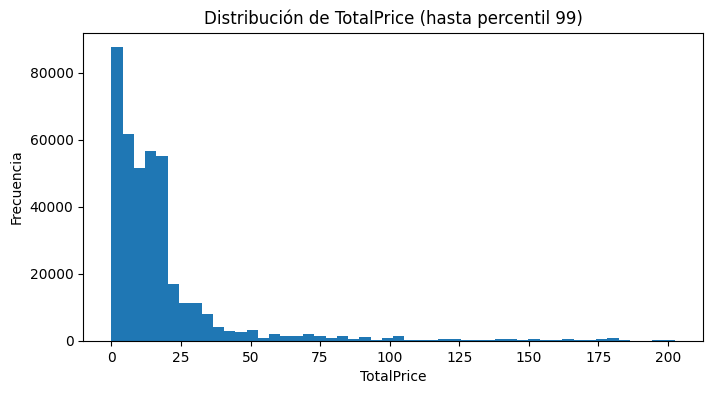

In [57]:
numeric_cols = ["Quantity", "UnitPrice", "TotalPrice"]

for col in numeric_cols:
    upper = df[col].quantile(0.99)
    
    plt.figure(figsize=(8,4))
    plt.hist(df[df[col] <= upper][col], bins=50)
    plt.title(f"Distribución de {col} (hasta percentil 99)")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

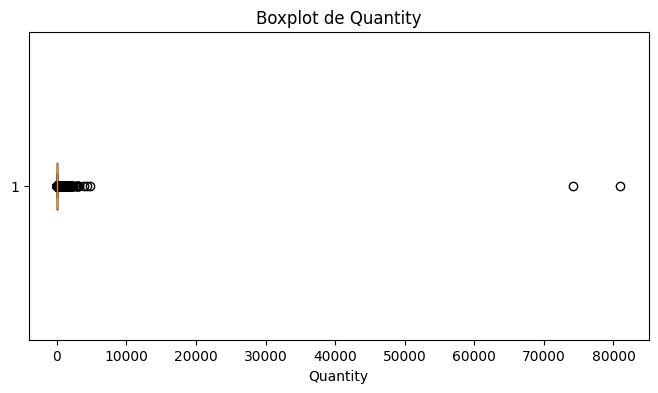

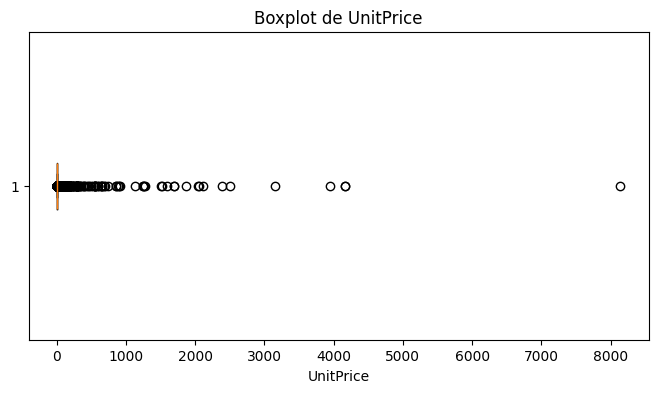

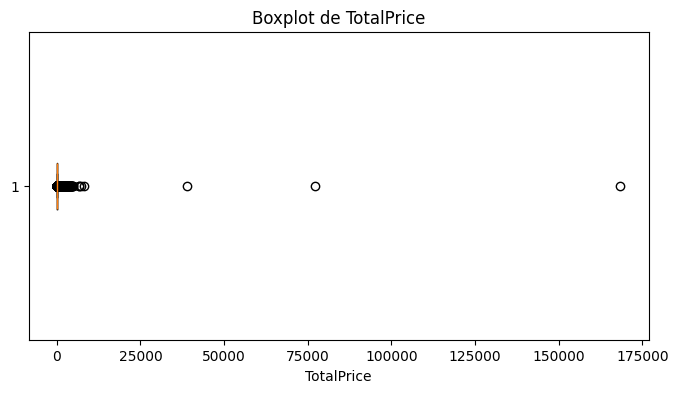

In [30]:
for col in numeric_cols:
    plt.figure(figsize=(8,4))
    plt.boxplot(df[col], vert=False)
    plt.title(f"Boxplot de {col}")
    plt.xlabel(col)
    plt.show()

Las distribuciones presentan un fuerte sesgo a la derecha, algo esperable en datos transaccionales de retail. Un pequeño grupo de observaciones concentra valores considerablemente mayores que la mayoría.

## 6. Construcción de variables RFM

La segmentación se realiza a nivel cliente, no a nivel transacción. Por ello, los datos se agregan en tres indicadores clave:

- **Recency**: días desde la última compra
- **Frequency**: número de compras o facturas únicas
- **Monetary**: gasto total acumulado

In [31]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
snapshot_date

Timestamp('2011-12-10 12:50:00')

In [32]:
rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalPrice": "sum"
}).reset_index()

In [33]:
rfm.columns = ["CustomerID", "Recency", "Frequency", "Monetary"]
rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [34]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


## 7. Análisis de distribución de RFM

Las variables RFM suelen presentar asimetría y valores extremos. Para evaluarlo, se revisan tanto histogramas como boxplots, ya que estas características pueden afectar negativamente el desempeño de K-Means si no se tratan adecuadamente.

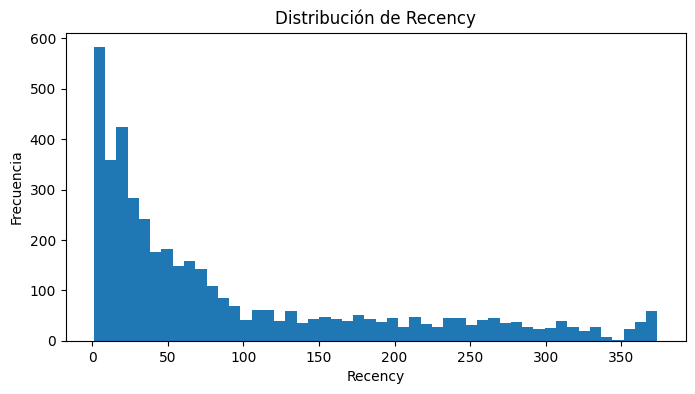

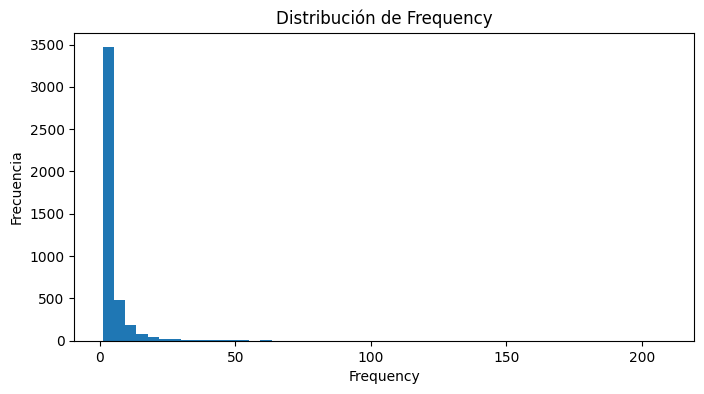

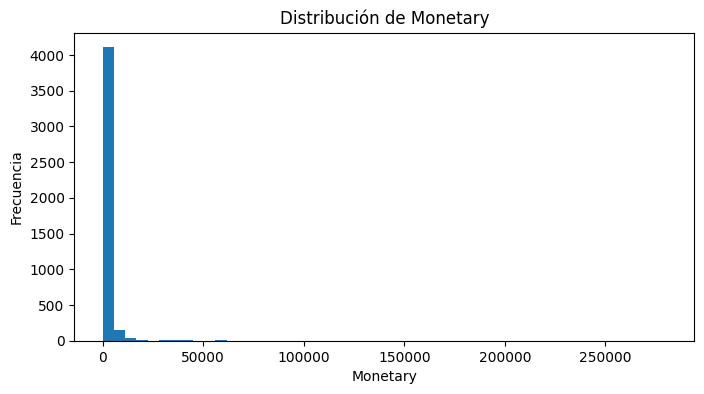

In [35]:
rfm_cols = ["Recency", "Frequency", "Monetary"]

for col in rfm_cols:
    plt.figure(figsize=(8,4))
    plt.hist(rfm[col], bins=50)
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

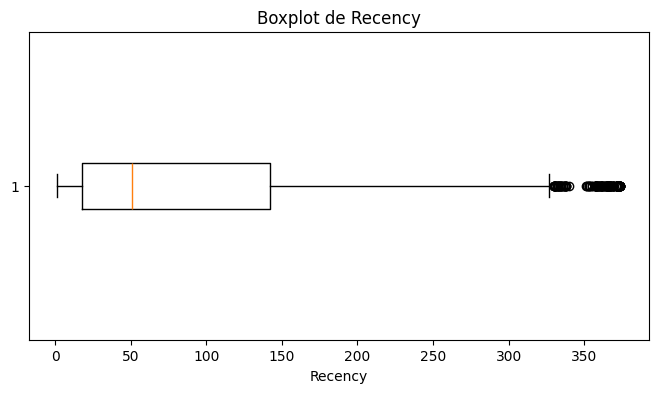

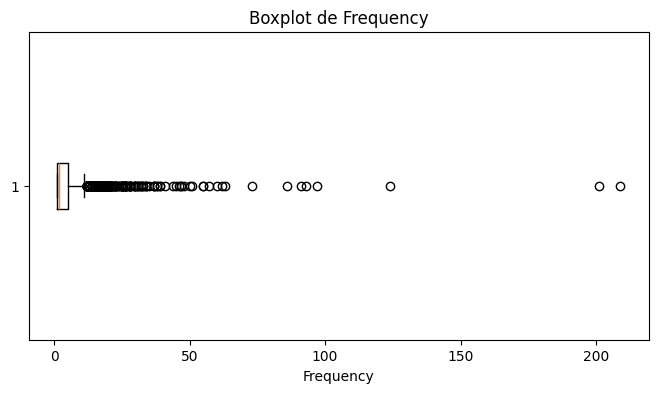

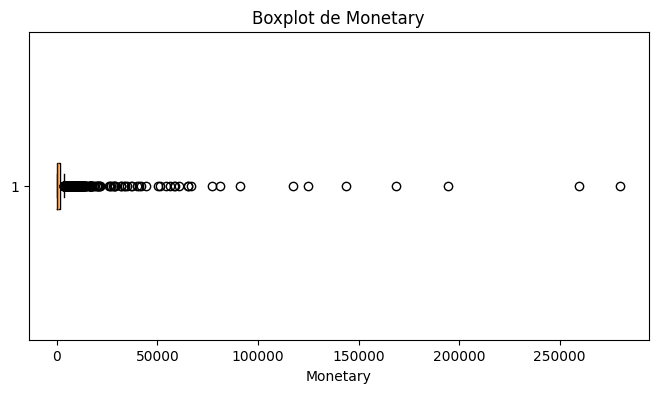

In [58]:
for col in rfm_cols:
    plt.figure(figsize=(8,4))
    plt.boxplot(rfm[col], vert=False)
    plt.title(f"Boxplot de {col}")
    plt.xlabel(col)
    plt.show()

## 8. Transformación logarítmica

Dado que `Frequency` y `Monetary` suelen estar altamente sesgadas, se aplica una transformación logarítmica para reducir el efecto de los valores extremos y mejorar la calidad del clustering.

In [36]:
rfm_log = rfm.copy()

rfm_log["Recency"] = np.log1p(rfm_log["Recency"])
rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])
rfm_log["Monetary"] = np.log1p(rfm_log["Monetary"])

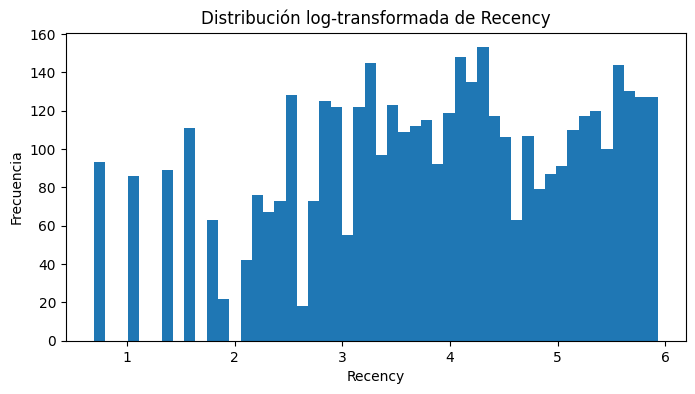

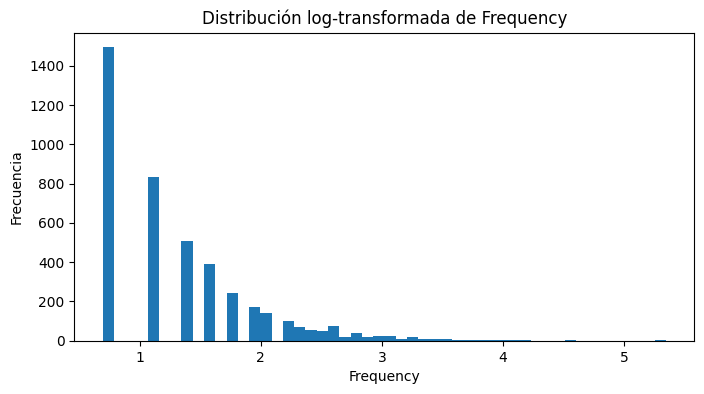

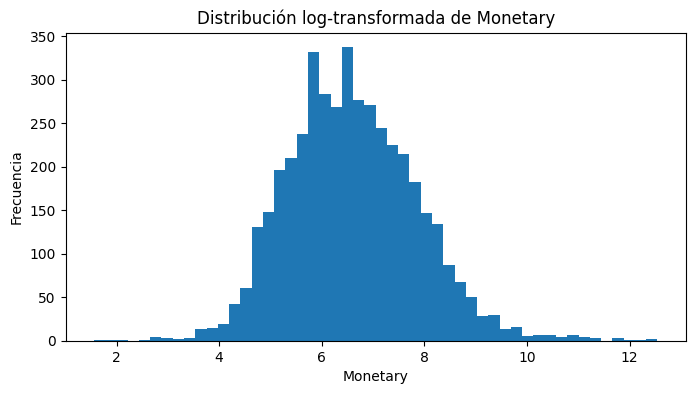

In [37]:
for col in rfm_cols:
    plt.figure(figsize=(8,4))
    plt.hist(rfm_log[col], bins=50)
    plt.title(f"Distribución log-transformada de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

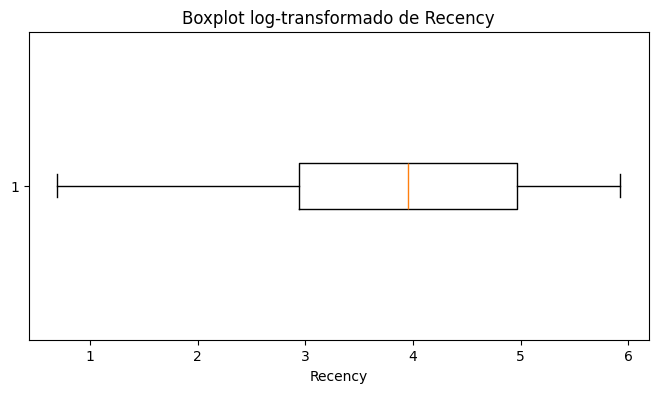

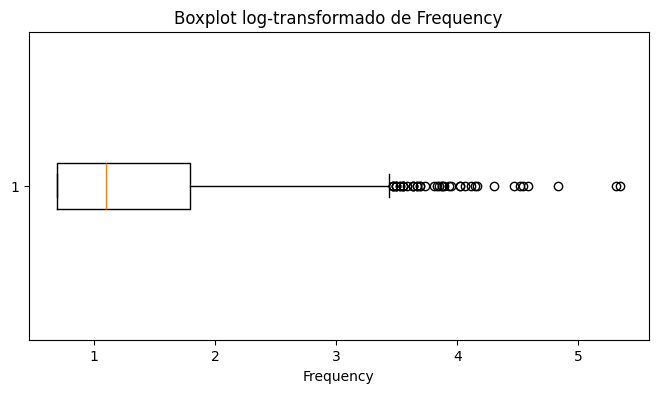

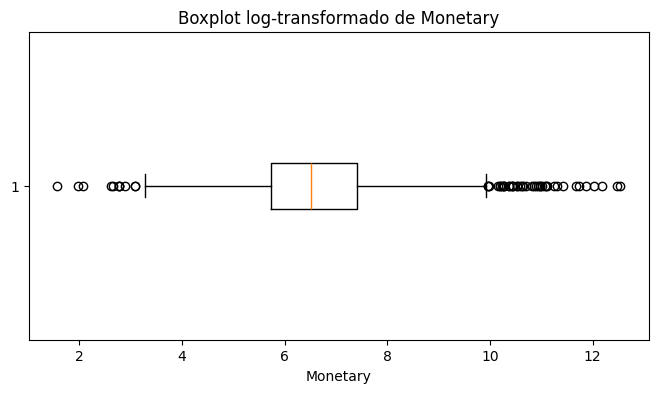

In [59]:
for col in rfm_cols:
    plt.figure(figsize=(8,4))
    plt.boxplot(rfm_log[col], vert=False)
    plt.title(f"Boxplot log-transformado de {col}")
    plt.xlabel(col)
    plt.show()

## 9. Escalamiento de variables

K-Means es un algoritmo basado en distancias, por lo que es necesario estandarizar las variables para evitar que una dimensión domine el proceso de agrupamiento por tener una escala mayor.

In [38]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log[["Recency", "Frequency", "Monetary"]])

In [39]:
rfm_scaled[:5]

array([[ 1.46199281, -0.95521426,  3.70622476],
       [-2.03873442,  1.07442519,  1.41184341],
       [ 0.37310424,  0.38630445,  0.7164889 ],
       [-0.62308592, -0.95521426,  0.6987394 ],
       [ 1.42455753, -0.95521426, -0.6189622 ]])

## 10. Selección del número de clusters

Para determinar el número más adecuado de grupos, se utiliza primero el método del codo, que evalúa cómo disminuye la suma de cuadrados intra-cluster a medida que aumenta `k`.

In [40]:
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(rfm_scaled)
    wcss.append(model.inertia_)

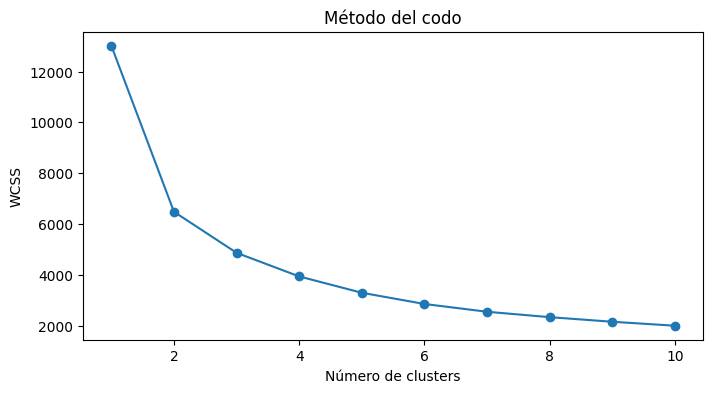

In [41]:
plt.figure(figsize=(8,4))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Método del codo")
plt.xlabel("Número de clusters")
plt.ylabel("WCSS")
plt.show()

Para complementar el método del codo, también se utiliza el **Silhouette Score**, que permite evaluar qué tan bien separados están los clusters entre sí.

In [42]:
sil_scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(rfm_scaled)
    score = silhouette_score(rfm_scaled, labels)
    sil_scores.append(score)

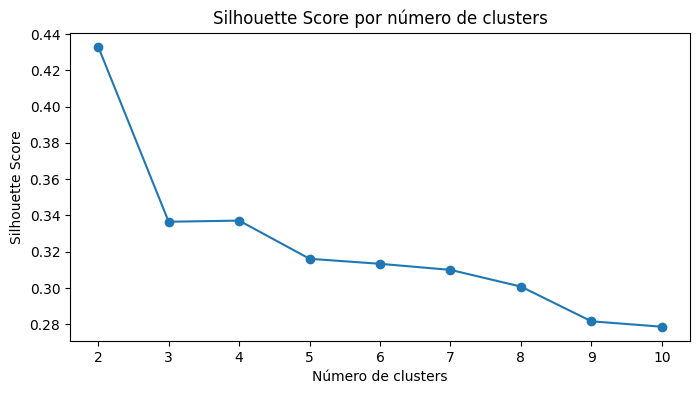

In [43]:
plt.figure(figsize=(8,4))
plt.plot(range(2, 11), sil_scores, marker="o")
plt.title("Silhouette Score por número de clusters")
plt.xlabel("Número de clusters")
plt.ylabel("Silhouette Score")
plt.show()

Con base en el método del codo y el Silhouette Score, se selecciona el número final de clusters. En este caso, se utilizará `k = 4`, ya que ofrece un equilibrio razonable entre separación e interpretabilidad.

In [44]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)
rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346.0,326,1,77183.60,2
1,12347.0,2,7,4310.00,1
2,12348.0,75,4,1797.24,2
3,12349.0,19,1,1757.55,0
4,12350.0,310,1,334.40,3


## 11. Perfilamiento de clusters

Una vez asignados los clusters, se analizan los valores promedio de RFM en cada grupo para comprender el comportamiento de los clientes segmentados.

Dado que las variables tienen escalas distintas, también se utiliza una visualización estandarizada para comparar mejor los perfiles relativos entre clusters.

In [45]:
cluster_summary = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(2)
cluster_summary

,Recency,Frequency,Monetary
Cluster,,,
0,18.12,2.15,551.82
1,12.13,13.71,8074.27
2,71.08,4.08,1802.83
3,182.50,1.32,343.45


In [46]:
cluster_counts = rfm["Cluster"].value_counts().sort_index()
cluster_counts

Cluster
0     837
1     716
2    1173
3    1612
Name: count, dtype: int64

In [47]:
cluster_summary["Count"] = cluster_counts
cluster_summary

,Recency,Frequency,Monetary,Count
Cluster,,,,
0,18.12,2.15,551.82,837
1,12.13,13.71,8074.27,716
2,71.08,4.08,1802.83,1173
3,182.50,1.32,343.45,1612


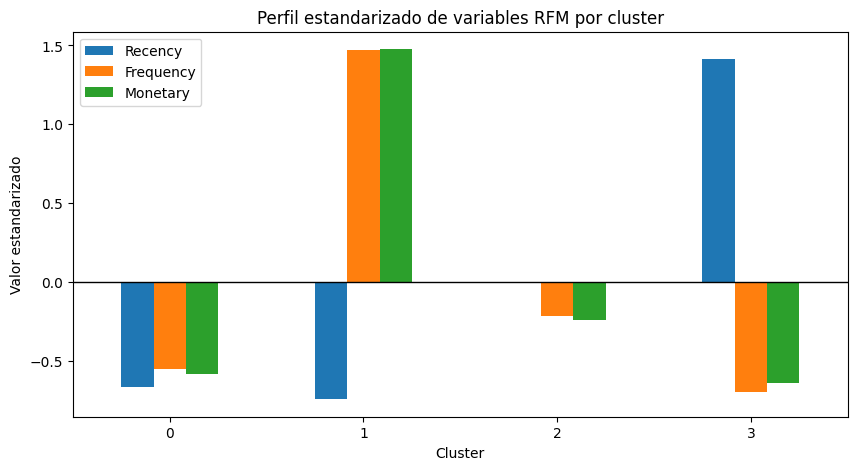

In [60]:
cluster_profile_std = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean()
cluster_profile_std = (cluster_profile_std - cluster_profile_std.mean()) / cluster_profile_std.std()

cluster_profile_std.plot(kind="bar", figsize=(10,5))
plt.title("Perfil estandarizado de variables RFM por cluster")
plt.ylabel("Valor estandarizado")
plt.xticks(rotation=0)
plt.axhline(0, color="black", linewidth=1)
plt.show()

## 12. Visualización de clusters con PCA

Como el clustering se realiza en un espacio multidimensional, se utiliza PCA para proyectar las variables estandarizadas en dos dimensiones y facilitar su visualización.

Además, se revisa la proporción de varianza explicada por los dos primeros componentes para interpretar con mayor cautela esta representación bidimensional.

In [61]:
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)

print("Varianza explicada por PC1 y PC2:", pca.explained_variance_ratio_)
print("Varianza explicada acumulada:", pca.explained_variance_ratio_.sum())

Varianza explicada por PC1 y PC2: [0.75102042 0.18759201]
Varianza explicada acumulada: 0.9386124314129809


In [50]:
pca_df = pd.DataFrame(rfm_pca, columns=["PC1", "PC2"])
pca_df["Cluster"] = rfm["Cluster"].values
pca_df.head()

,PC1,PC2,Cluster
0,0.872658,2.686758,2
1,2.550260,-0.804427,1
2,0.475142,0.746121,2
3,0.145832,-0.460480,0
4,-1.688990,0.676555,3


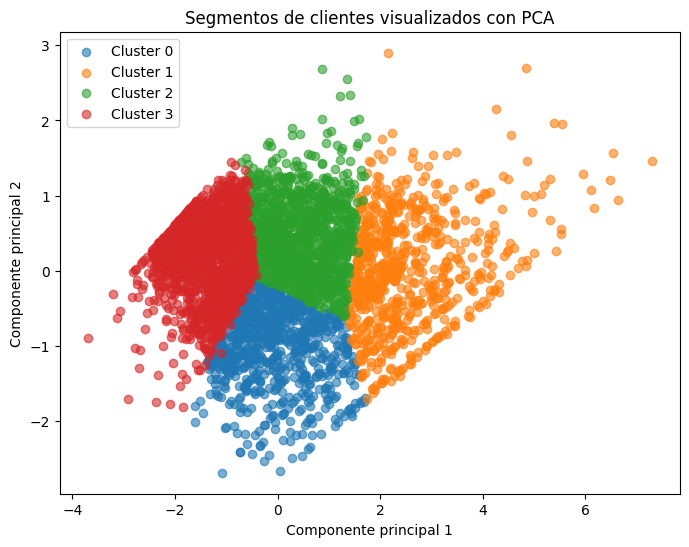

In [51]:
plt.figure(figsize=(8,6))

for cluster in sorted(pca_df["Cluster"].unique()):
    subset = pca_df[pca_df["Cluster"] == cluster]
    plt.scatter(subset["PC1"], subset["PC2"], label=f"Cluster {cluster}", alpha=0.6)

plt.title("Segmentos de clientes visualizados con PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend()
plt.show()

## 13. Interpretación de negocio

Para que la segmentación sea útil desde un punto de vista empresarial, cada cluster debe interpretarse según su perfil RFM observado.

La asignación de nombres no depende del número del cluster, sino de los valores promedio de recencia, frecuencia y gasto de cada grupo.

In [53]:
cluster_summary

,Recency,Frequency,Monetary,Count
Cluster,,,,
0,18.12,2.15,551.82,837
1,12.13,13.71,8074.27,716
2,71.08,4.08,1802.83,1173
3,182.50,1.32,343.45,1612


In [62]:
segment_map = {
    0: "Clientes recientes de bajo valor",
    1: "Clientes VIP",
    2: "Clientes regulares o potencialmente leales",
    3: "Clientes en riesgo"
}

rfm["Segmento"] = rfm["Cluster"].map(segment_map)
rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster,Segmento
0,12346.0,326,1,77183.60,2,Clientes regulares o potencialmente leales
1,12347.0,2,7,4310.00,1,Clientes VIP
2,12348.0,75,4,1797.24,2,Clientes regulares o potencialmente leales
3,12349.0,19,1,1757.55,0,Clientes recientes de bajo valor
4,12350.0,310,1,334.40,3,Clientes en riesgo


In [63]:
cluster_summary.sort_values(by="Monetary", ascending=False)

,Recency,Frequency,Monetary,Count
Cluster,,,,
1,12.13,13.71,8074.27,716
2,71.08,4.08,1802.83,1173
0,18.12,2.15,551.82,837
3,182.50,1.32,343.45,1612


In [64]:
cluster_summary.sort_values(by=["Recency", "Frequency", "Monetary"], ascending=[True, False, False])

,Recency,Frequency,Monetary,Count
Cluster,,,,
1,12.13,13.71,8074.27,716
0,18.12,2.15,551.82,837
2,71.08,4.08,1802.83,1173
3,182.50,1.32,343.45,1612


## 14. Exportación de resultados

La tabla RFM procesada y la segmentación final de clientes se exportan para su uso posterior en dashboards o análisis de negocio.

In [56]:
rfm.to_csv("../data/processed/customer_segments.csv", index=False)
cluster_summary.to_csv("../data/processed/rfm_table.csv", index=False)

## 15. Conclusión

Este proyecto transformó datos transaccionales en segmentos de clientes accionables mediante el uso de variables RFM y clustering con K-Means.

La segmentación permitió identificar diferencias relevantes en el comportamiento de compra según la antigüedad de la última compra, la frecuencia y el gasto acumulado. Estos grupos pueden servir para apoyar decisiones como:

- campañas de retención para clientes valiosos
- estrategias de reactivación para clientes inactivos
- acciones de marketing personalizadas para compradores ocasionales
- programas de fidelización para clientes frecuentes

En conjunto, el proyecto demuestra cómo el aprendizaje no supervisado puede generar valor de negocio a partir de datos de retail.